In [2]:
import pandas as pd
import numpy as np

# Dataset load karna jo humne data folder mein rakha hai
df = pd.read_csv('../data/Loan_default.csv')

# Dataset ki shape aur shuru ki 5 rows dekhna
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
# 1. Sabhi columns ke naam dekhna
print("Columns in Dataset:")
print(df.columns.tolist())

# 2. Missing values check karna
print("\nMissing Values Count per Column:")
print(df.isnull().sum())

Columns in Dataset:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']

Missing Values Count per Column:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [4]:
# 1. Unnecessary columns drop karna (jaise LoanID, kyunki yeh prediction mein help nahi karega)
if 'LoanID' in df.columns:
    df = df.drop(columns=['LoanID'])

# 2. Categorical text columns ko One-Hot Encoding se numbers mein convert karna
df_encoded = pd.get_dummies(df, drop_first=True)

# 3. Features (X) aur Target (y) ko alag karna
X = df_encoded.drop(columns=['Default'])
y = df_encoded['Default']

# 4. Data ko Training aur Testing sets mein divide karna (80% Train, 20% Test)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (204277, 24)
X_test shape: (51070, 24)


In [5]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

# 1. XGBoost Model initialize aur train karna
print("Training XGBoost model (yeh thoda time le sakta hai kyunki data bada hai)...")
model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# 2. Predictions aur Evaluation
y_pred_proba = model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"\nModel AUC-ROC Score: {auc_score:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, model.predict(X_test)))

Training XGBoost model (yeh thoda time le sakta hai kyunki data bada hai)...

Model AUC-ROC Score: 0.7556

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45170
           1       0.62      0.07      0.13      5900

    accuracy                           0.89     51070
   macro avg       0.76      0.53      0.54     51070
weighted avg       0.86      0.89      0.85     51070



In [6]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np

# Class imbalance calculate karna (non-defaults vs defaults ka ratio)
scale_pos_weight_val = (len(y_train) - sum(y_train)) / sum(y_train)

# Behtar parameters ke sath XGBoost train karna
print("Training tuned XGBoost model with scale_pos_weight...")
better_model = XGBClassifier(
    n_estimators=150, 
    learning_rate=0.05, 
    max_depth=5, 
    scale_pos_weight=scale_pos_weight_val,
    random_state=42
)
better_model.fit(X_train, y_train)

# New Predictions aur Evaluation
y_pred_proba_new = better_model.predict_proba(X_test)[:, 1]
new_auc_score = roc_auc_score(y_test, y_pred_proba_new)

print(f"\nUpdated Model AUC-ROC Score: {new_auc_score:.4f}")
print("\nUpdated Classification Report:")
print(classification_report(y_test, better_model.predict(X_test)))

Training tuned XGBoost model with scale_pos_weight...

Updated Model AUC-ROC Score: 0.7579

Updated Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.70      0.80     45170
           1       0.23      0.68      0.34      5900

    accuracy                           0.70     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.70      0.75     51070



Model successfully saved as '../src/loan_model.pkl'

Calculating SHAP values for model explanation...


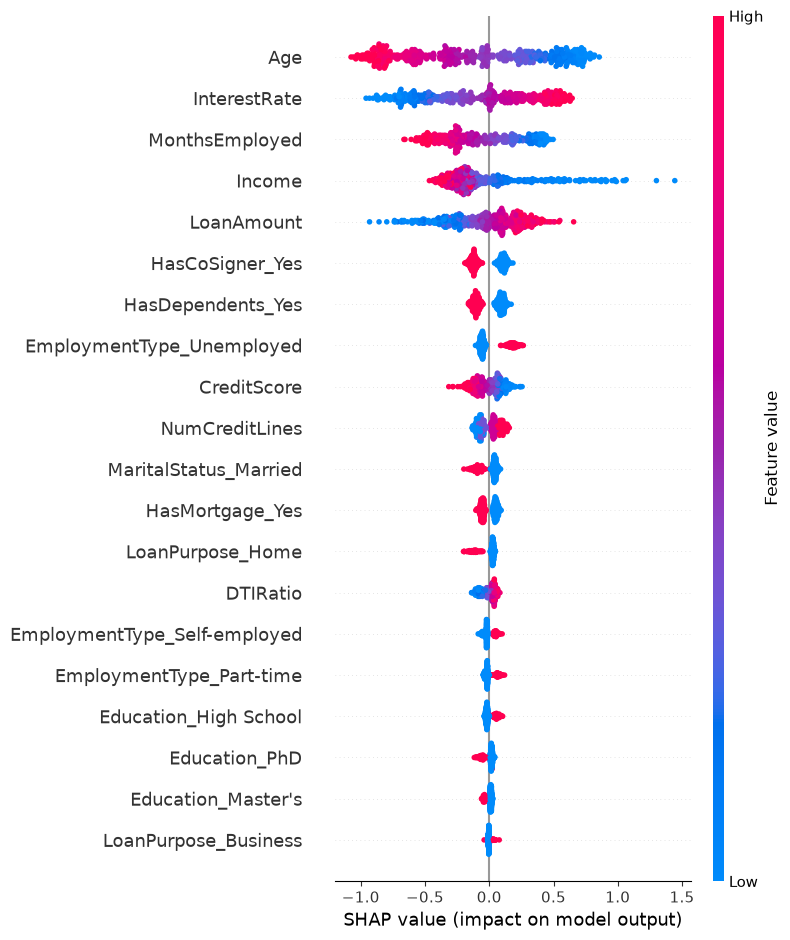

In [7]:
import joblib
import os
import shap

# 1. Model ko save karna taaki API mein use ho sake
os.makedirs("../src", exist_ok=True)
joblib.dump(better_model, "../src/loan_model.pkl")
print("Model successfully saved as '../src/loan_model.pkl'")

# 2. SHAP Explainability (Yeh thoda time le sakta hai)
print("\nCalculating SHAP values for model explanation...")
explainer = shap.TreeExplainer(better_model)
# Chote sample par SHAP calculate karte hain taaki fast chale
shap_values = explainer(X_test.iloc[:500])

# SHAP Summary Plot
shap.summary_plot(shap_values, X_test.iloc[:500])

In [9]:
import joblib
import os

# Model ko save karna
os.makedirs("../src", exist_ok=True)
joblib.dump(better_model, "../src/loan_model.pkl")
print("Model successfully saved as '../src/loan_model.pkl'")

Model successfully saved as '../src/loan_model.pkl'
